# Lab 4: Hill-Climbing Search with the N-Queens Problem

Implement Hill-Climbing for N-Queens, plot the evaluation score over iterations, explain why it can stop without a solution, and compare it with Random-Restart Hill-Climbing.

*A fixed random seed is set in the first code cell so the numbers quoted in the written answers match the printed output on every run.*

## 1. Representing a State
The state is a list: the **index is the column** and the **value is the row** of that column's queen. Each column therefore always holds exactly one queen.

### Task 1

In [1]:
import random
random.seed(42)   # reproducible results

state = [1, 3, 0, 2]

print("State:", state)

State: [1, 3, 0, 2]


## 2. Random Initial State

In [2]:
def random_state(n):
    return [random.randrange(n) for _ in range(n)]

state = random_state(8)

print("Random initial state:", state)

Random initial state: [1, 0, 4, 3, 3, 2, 1, 1]


## 3. Evaluation Function
We count pairs of queens that attack each other (same row or same diagonal; same column is impossible by construction). The evaluation score is **− (number of conflicts)**, so higher is better and **0 is the best possible score**.

In [3]:
def count_conflicts(state):
    conflicts = 0
    n = len(state)

    for i in range(n):
        for j in range(i + 1, n):

            # Queens in the same row
            if state[i] == state[j]:
                conflicts += 1

            # Queens on the same diagonal
            elif abs(state[i] - state[j]) == abs(i - j):
                conflicts += 1

    return conflicts

In [4]:
state = [1, 3, 0, 2]

print("Conflicts:", count_conflicts(state))

Conflicts: 0


In [5]:
def evaluation(state):
    return -count_conflicts(state)

state = [1, 3, 0, 2]

print("Evaluation score:", evaluation(state))

Evaluation score: 0


## 4. Generating Neighbors
A neighbor moves one queen to another row in its own column, giving N × (N − 1) neighbors per state.

In [6]:
def get_neighbors(state):
    neighbors = []
    n = len(state)

    for col in range(n):
        for row in range(n):

            if row != state[col]:
                neighbor = state.copy()
                neighbor[col] = row
                neighbors.append(neighbor)

    return neighbors

In [7]:
state = [1, 3, 0, 2]

neighbors = get_neighbors(state)

print("Number of neighbors:", len(neighbors))
print("First five neighbors:")

for neighbor in neighbors[:5]:
    print(neighbor)

Number of neighbors: 12
First five neighbors:
[0, 3, 0, 2]
[2, 3, 0, 2]
[3, 3, 0, 2]
[1, 0, 0, 2]
[1, 1, 0, 2]


## 5. Basic Hill-Climbing
Start from a random state, move to the best neighbor while it strictly improves the score, and stop when no neighbor is better. `scores` records the evaluation score at every step.

*Note: `Iterations = len(scores)` counts the states evaluated, i.e. the starting state plus each accepted move.*

In [8]:
def hill_climbing(n):

    current = random_state(n)
    scores = []

    while True:

        # Evaluate the current state
        current_score = evaluation(current)
        scores.append(current_score)

        # Generate all neighboring states
        neighbors = get_neighbors(current)

        # Find the best neighbor
        best_neighbor = max(neighbors, key=evaluation)
        best_score = evaluation(best_neighbor)

        # Stop if no neighbor improves the current score
        if best_score <= current_score:
            break

        # Move to the better neighbor
        current = best_neighbor

    return current, scores

In [9]:
solution, scores = hill_climbing(8)

print("Final state:", solution)
print("Final conflicts:", count_conflicts(solution))
print("Final evaluation score:", evaluation(solution))
print("Number of iterations:", len(scores))

if count_conflicts(solution) == 0:
    print("A valid solution was found.")
else:
    print("Hill-Climbing stopped without finding a solution.")

Final state: [6, 2, 7, 1, 4, 0, 5, 3]
Final conflicts: 0
Final evaluation score: 0
Number of iterations: 6
A valid solution was found.


### Why can the algorithm stop without solving the problem?
It stops when the current state is better than all its immediate neighbors, even though the score is still below zero. This is a **local maximum**. A **plateau** (neighbors all equal to the current score) stops this implementation too, because it only accepts strictly better moves. A solution with score 0 may exist elsewhere in the state space.

## 6. Visualizing the Chessboard

In [10]:
def print_board(state):

    n = len(state)

    for row in range(n):

        line = ""

        for col in range(n):

            if state[col] == row:
                line += "Q "
            else:
                line += ". "

        print(line)

In [11]:
print_board(solution)

. . . . . Q . . 
. . . Q . . . . 
. Q . . . . . . 
. . . . . . . Q 
. . . . Q . . . 
. . . . . . Q . 
Q . . . . . . . 
. . Q . . . . . 


## 7. Plotting the Evaluation Score

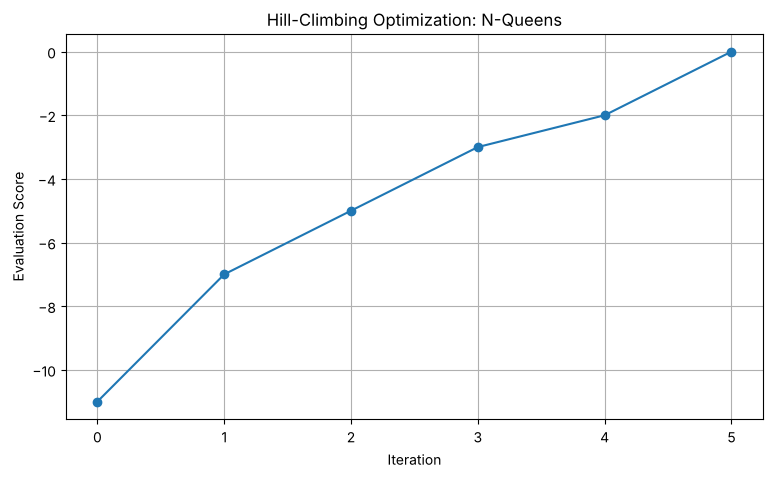

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    range(len(scores)),
    scores,
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Evaluation Score")
plt.title("Hill-Climbing Optimization: N-Queens")

plt.grid(True)
plt.show()

### Interpret the Graph
In the run plotted above the scores were `[-11, -7, -5, -3, -2, 0]`: five accepted moves from −11 conflicts down to a solution.

1. **Does the score increase as the algorithm moves to better states?** Yes. It rose at every step (−11 → −7 → −5 → −3 → −2 → 0). The largest gain came first (+4) and the gains shrank as the state got closer to a solution.
2. **Does the score decrease during an accepted move?** No. The algorithm accepts a neighbor only if its score is strictly higher, so the curve is non-decreasing.
3. **What happens when there is no better neighbor?** The loop stops (`best_score <= current_score`). The last point on the graph is the final state.
4. **What does a score of zero mean?** Zero conflicts: no two queens attack each other, so the board is a valid solution. It is the best possible score because the score is −(number of conflicts) and conflicts cannot be negative.
5. **Can the algorithm stop below zero?** Yes. If every neighbor is equal or worse, the search stops at a local maximum or plateau with conflicts remaining. This happened in all eight Task 2 runs below (final scores −1 or −2).

## 8. Different Board Sizes
### Task 2

In [13]:
for n in [4, 8, 10, 12]:

    solution, scores = hill_climbing(n)

    print(
        f"N = {n:2d} | "
        f"Conflicts = {count_conflicts(solution):2d} | "
        f"Iterations = {len(scores):3d} | "
        f"Solved = {count_conflicts(solution) == 0}"
    )

N =  4 | Conflicts =  1 | Iterations =   2 | Solved = False
N =  8 | Conflicts =  1 | Iterations =   4 | Solved = False
N = 10 | Conflicts =  1 | Iterations =   5 | Solved = False
N = 12 | Conflicts =  2 | Iterations =   6 | Solved = False


In [14]:
import pandas as pd

rows = []
for n, runs in [(4, 2), (8, 3), (10, 3)]:
    for run in range(1, runs + 1):
        sol, sc = hill_climbing(n)
        c = count_conflicts(sol)
        rows.append({"N": n, "Run": run, "Final Conflicts": c, "Iterations": len(sc), "Solved?": c == 0})

pd.DataFrame(rows)

,N,Run,Final Conflicts,Iterations,Solved?
0,4,1,1,2,False
1,4,2,1,3,False
2,8,1,1,4,False
3,8,2,1,5,False
4,8,3,2,3,False
5,10,1,2,4,False
6,10,2,1,5,False
7,10,3,2,5,False


**Observations:** None of the eight runs above found a solution; they stopped at 1 or 2 conflicts after only 2 to 5 iterations. The same board size does **not** always give the same result, because the starting state is random and each start leads to a different hill. For N = 8, runs 1 to 3 ended with 1, 1 and 2 conflicts, while the earlier single N = 8 run (Section 5) reached 0 conflicts. Basic Hill-Climbing therefore solves N = 8 only occasionally (about 14 % of runs, measured in Section 11), and the success chance drops as N grows.

## 9. Random-Restart Hill-Climbing
Run Hill-Climbing from new random states until a solution is found or the restart limit is reached, keeping the best state seen.

In [15]:
def random_restart_hill_climbing(n, max_restarts=100):

    best_state = None
    best_score = float("-inf")
    best_scores = []

    for restart in range(max_restarts):

        # Start a new Hill-Climbing run
        state, scores = hill_climbing(n)

        score = evaluation(state)

        # Keep the best state found so far
        if score > best_score:
            best_state = state
            best_score = score

        # Record the best score after this restart
        best_scores.append(best_score)

        # A score of zero means a valid solution
        if best_score == 0:
            return best_state, restart + 1, best_scores

    return best_state, max_restarts, best_scores

In [16]:
solution, restarts, best_scores = (
    random_restart_hill_climbing(8, max_restarts=100)
)

print("Final state:", solution)
print("Final conflicts:", count_conflicts(solution))
print("Restarts performed:", restarts)

if count_conflicts(solution) == 0:
    print("A valid solution was found.")
else:
    print("No solution was found within the restart limit.")

print_board(solution)

Final state: [3, 0, 4, 7, 1, 6, 2, 5]
Final conflicts: 0
Restarts performed: 5
A valid solution was found.
. Q . . . . . . 
. . . . Q . . . 
. . . . . . Q . 
Q . . . . . . . 
. . Q . . . . . 
. . . . . . . Q 
. . . . . Q . . 
. . . Q . . . . 


## 10. Random-Restart Progress

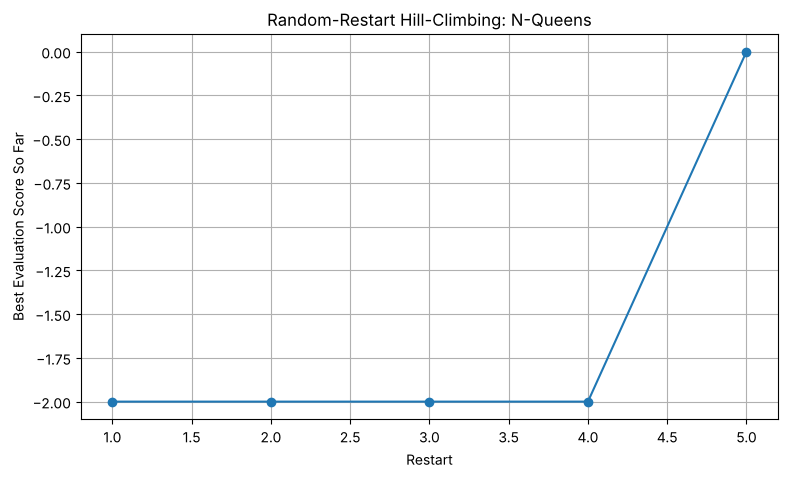

In [17]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(best_scores) + 1),
    best_scores,
    marker="o"
)

plt.xlabel("Restart")
plt.ylabel("Best Evaluation Score So Far")
plt.title("Random-Restart Hill-Climbing: N-Queens")

plt.grid(True)
plt.show()

The curve is non-decreasing because the best-so-far score is retained. A single point means a solution was found on the first restart. This graph differs from the single-run graph: that one shows the score *during* one search, this one shows the best score *across* repeated searches.

## 11. Comparing Basic and Random-Restart Hill-Climbing
### Task 3

In [18]:
print("Basic Hill-Climbing")
print("-------------------")

for i in range(5):

    state, scores = hill_climbing(8)
    conflicts = count_conflicts(state)

    print(
        f"Run {i + 1}: "
        f"Conflicts = {conflicts}, "
        f"Iterations = {len(scores)}, "
        f"Solved = {conflicts == 0}"
    )


print("\nRandom-Restart Hill-Climbing")
print("----------------------------")

for i in range(5):

    state, restarts, best_scores = (
        random_restart_hill_climbing(8, max_restarts=100)
    )

    conflicts = count_conflicts(state)

    print(
        f"Run {i + 1}: "
        f"Conflicts = {conflicts}, "
        f"Restarts = {restarts}, "
        f"Solved = {conflicts == 0}"
    )

Basic Hill-Climbing
-------------------
Run 1: Conflicts = 1, Iterations = 3, Solved = False
Run 2: Conflicts = 1, Iterations = 5, Solved = False
Run 3: Conflicts = 1, Iterations = 5, Solved = False
Run 4: Conflicts = 2, Iterations = 4, Solved = False
Run 5: Conflicts = 2, Iterations = 4, Solved = False

Random-Restart Hill-Climbing
----------------------------
Run 1: Conflicts = 0, Restarts = 17, Solved = True
Run 2: Conflicts = 0, Restarts = 1, Solved = True
Run 3: Conflicts = 0, Restarts = 14, Solved = True
Run 4: Conflicts = 0, Restarts = 7, Solved = True
Run 5: Conflicts = 0, Restarts = 17, Solved = True


In [19]:
# Measure the per-run success probability p of basic hill-climbing (N = 8) over many runs
runs = 1000
p = sum(count_conflicts(hill_climbing(8)[0]) == 0 for _ in range(runs)) / runs
print(f"Estimated success probability of one basic run (N = 8): p = {p:.3f}")

for k in (1, 5, 10, 20):
    print(f"P(at least one success in {k:2d} restarts) = 1 - (1 - p)^{k} = {1 - (1 - p) ** k:.4f}")

Estimated success probability of one basic run (N = 8): p = 0.137
P(at least one success in  1 restarts) = 1 - (1 - p)^1 = 0.1370
P(at least one success in  5 restarts) = 1 - (1 - p)^5 = 0.5213
P(at least one success in 10 restarts) = 1 - (1 - p)^10 = 0.7709
P(at least one success in 20 restarts) = 1 - (1 - p)^20 = 0.9475


**Task 3 answers** (seed 42; basic runs from the first listing, random-restart runs from the second)

1. **Did basic Hill-Climbing find a solution in every run?** No. None of the 5 runs succeeded; they stopped with 1 or 2 conflicts. Over 1000 runs the measured success probability of one basic run at N = 8 is p ≈ 0.137.
2. **Did Random-Restart improve the results?** Yes. All 5 random-restart runs found a valid solution (0 conflicts).
3. **How many restarts were needed?** 17, 1, 14, 7 and 17 (mean 11.2). That is consistent with the expected number of attempts 1/p ≈ 7 for a 13.7 % per-run success rate; with only five runs the sample varies a lot.
4. **Did any run hit the restart limit?** No. All stopped well before 100 restarts. The chance of failing all 100 restarts at N = 8 is (1 − p)^100 ≈ 4 × 10⁻⁷, which is tiny but not zero.
5. **Why does Random-Restart raise the success probability without guaranteeing success within a fixed number of attempts?** Each restart is an independent chance with success probability p > 0, so P(at least one success in k restarts) = 1 − (1 − p)^k. From the table above this is 0.52 for k = 5, 0.77 for k = 10 and 0.95 for k = 20. The value approaches 1 as k grows but is strictly below 1 for any finite k, so a fixed limit never gives a guarantee.

## 12. Extension Task: N = 20

In [20]:
print("N = 20")

basic_solution, basic_scores = hill_climbing(20)
print("\nBasic Hill-Climbing:")
print("Final conflicts:", count_conflicts(basic_solution))
print("Iterations:", len(basic_scores))
print("Solved:", count_conflicts(basic_solution) == 0)

rr_solution, rr_restarts, rr_scores = random_restart_hill_climbing(20, max_restarts=100)
print("\nRandom-Restart Hill-Climbing:")
print("Final conflicts:", count_conflicts(rr_solution))
print("Restarts:", rr_restarts)
print("Solved:", count_conflicts(rr_solution) == 0)

# Success rate of basic hill-climbing at N = 20
p20 = sum(count_conflicts(hill_climbing(20)[0]) == 0 for _ in range(200)) / 200
print(f"\nBasic Hill-Climbing success rate at N = 20 over 200 runs: {p20:.3f}")

N = 20

Basic Hill-Climbing:
Final conflicts: 3
Iterations: 7
Solved: False



Random-Restart Hill-Climbing:
Final conflicts: 0
Restarts: 34
Solved: True



Basic Hill-Climbing success rate at N = 20 over 200 runs: 0.020


**Results for N = 20** (seed 42)

| Algorithm | Final conflicts | Iterations / Restarts | Solved? |
|---|---:|---:|---|
| Basic Hill-Climbing | 3 | 7 iterations | No |
| Random-Restart Hill-Climbing | 0 | 34 restarts | Yes |

**Comparison:** Basic Hill-Climbing stopped at a local maximum with 3 conflicts. Over 200 runs it succeeded only about 2 % of the time at N = 20 (4 of 200), compared with about 14 % at N = 8. Random-Restart solved the problem after 34 restarts, close to the roughly 50 attempts expected when p ≈ 0.02.

**Effect of the number of queens:** The state space grows from 8^8 ≈ 1.7 × 10⁷ states to 20^20 ≈ 10²⁶, and each state has 380 neighbors instead of 56. Local maxima are far more common relative to solutions, so the per-run success probability p falls sharply. Many more restarts are then needed, and a fixed limit of 100 restarts fails with probability about (1 − 0.02)^100 ≈ 13 %.

**Effect of the random initial state:** The starting state decides which hill the search climbs. Two runs on the same board size can end at different conflict counts, which is why the results change from run to run and why a seed is needed for reproducible numbers.

## 13. Lab Questions

**Q1. What is the purpose of the evaluation function in Hill-Climbing?**
It assigns every state a numeric quality (here −conflicts) so the algorithm can compare neighbors, choose the best one, and know when no further improvement is possible. It defines the "hill" being climbed.

**Q2. Why is an evaluation score of zero the best result?**
The score is −(number of conflicts) and conflicts cannot be negative, so 0 is the maximum possible. It means no two queens attack each other, i.e. the puzzle is solved.

**Q3. What is the difference between a local maximum and a global maximum?**
A local maximum is a state whose score is at least as good as all of its immediate neighbors, but a better state may exist elsewhere. A global maximum is a state with the highest score in the entire state space (score 0 for N-Queens whenever a solution exists). Every global maximum is also a local maximum, but not every local maximum is global.

**Q4. Why can basic Hill-Climbing stop without finding a solution even when one exists?**
It only looks at immediate neighbors and accepts only strictly better moves. At a local maximum, or on a plateau, no neighbor is better, so it stops even though a solution exists elsewhere. In this notebook the basic runs ended with 1 or 2 conflicts, and only about 14 % of N = 8 runs succeed.

**Q5. Does reaching a local maximum always mean the algorithm has failed?**
No. If the local maximum has score 0 it is also the global maximum and the goal has been reached. It is a failure only when the score is below 0.

**Q6. For N = 8, how many neighbors does each state have?**
8 × 7 = 56: each of the 8 columns has one queen that can move to any of the 7 other rows.

**Q7. What does the evaluation-score graph tell you about the behavior of Hill-Climbing?**
The score never decreases, since only improving moves are accepted. It usually improves quickly at first and then flattens, and the final point is where the search stopped. A final value of 0 means success, and a negative value means it ended at a local maximum.

**Q8. Explain probabilistic completeness in your own words.**
If every attempt is independent and has some nonzero chance p of succeeding, then the chance that at least one of k attempts succeeds, 1 − (1 − p)^k, gets closer and closer to 1 as k grows. So with enough restarts a solution will almost surely be found, but no finite number of restarts makes it certain.

**Q9. Why does Random-Restart Hill-Climbing improve the chance of finding a solution?**
Each restart begins from a new random state, i.e. a different hill, so being stuck on one local maximum does not end the search. Several independent attempts multiply the chances: at p ≈ 0.137 the success probability is about 0.52 after 5 restarts and 0.95 after 20.

**Q10. Does probabilistic completeness guarantee a solution within 100 restarts?**
No. It describes the limit as the number of attempts goes to infinity. For a finite limit the success probability 1 − (1 − p)^100 is below 1. At N = 8 the failure chance is about 4 × 10⁻⁷, so it is negligible, but at N = 20 (p ≈ 0.02) it is about 13 %.

## Key Takeaway
Hill-Climbing repeatedly improves the current state until no better neighbor exists. It may reach the goal, or it may stop at a non-goal local maximum. Random restarts give extra independent chances to succeed, but success within a fixed number of attempts is still not guaranteed.